In [1]:
from skimage import data
import matplotlib.pyplot as plt
import numpy as np

(512, 512) uint8


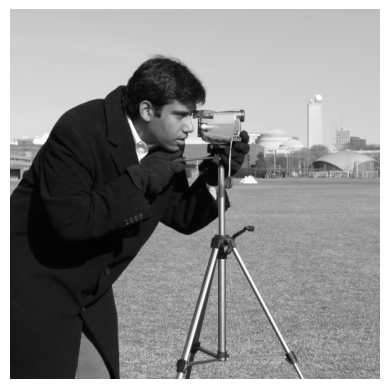

In [2]:
img = data.camera()  # imagem em escala de cinza (uint8, 512x512)
print(img.shape, img.dtype)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

In [3]:
def implot(img, img_filt, nomefiltro, kernelsize):
  plt.figure(figsize=(10, 5))
  #img 1
  plt.subplot(1,2,1)
  plt.imshow(img, cmap='gray', vmin=0, vmax=255)
  plt.title('imagem original')
  plt.axis('off')
  #img 2
  plt.subplot(1,2,2)
  plt.imshow(img_filt, cmap='gray', vmin=0, vmax=255)
  plt.title(f'Filtro {nomefiltro} {kernelsize}')
  plt.axis('off')
  plt.show()

### 1 - Convolução manual

Duas funções de varredura da imagem (sem usar nenhuma função do OpenCV):

* convolucao(img, kernel): convolução 2D linear. Cada pixel de saída é a soma dos produtos entre a vizinhança e o kernel (invertido, como manda a definição de convolução).
* convolucao_nao_linear(img, tamanho, funcao): mesma varredura por janela deslizante, mas em vez de somar produtos aplica uma funcao sobre a vizinhança (mediana, moda, máximo...). Esses filtros não podem ser expressos como um kernel, por isso são não-lineares.

Nas bordas, a imagem é estendida repetindo os pixels da borda (padding).

In [4]:
def adicionar_padding(img, tamanho):
  # replica os pixels da borda para que a janela caiba em todos os pixels
  p = tamanho // 2
  return np.pad(img, ((p, p), (p, p)), mode='edge')


def convolucao(img, kernel):
  kernel = np.flip(kernel)  # convolução = correlação com o kernel invertido
  kh, kw = kernel.shape
  h, w = img.shape
  img_pad = adicionar_padding(img, kh).astype(np.float64)
  saida = np.zeros((h, w), dtype=np.float64)

  for i in range(h):
    for j in range(w):
      janela = img_pad[i:i + kh, j:j + kw]
      saida[i, j] = np.sum(janela * kernel)

  return np.clip(np.round(saida), 0, 255).astype(np.uint8)


def convolucao_nao_linear(img, tamanho, funcao):
  h, w = img.shape
  img_pad = adicionar_padding(img, tamanho)
  saida = np.zeros((h, w), dtype=np.uint8)

  for i in range(h):
    for j in range(w):
      janela = img_pad[i:i + tamanho, j:j + tamanho]
      saida[i, j] = funcao(janela)

  return saida

### 2 - Filtro de média (linear)

Substitui cada pixel pela média da vizinhança. Kernel com todos os valores iguais a 1/(k·k), aplicado com a função convolucao.

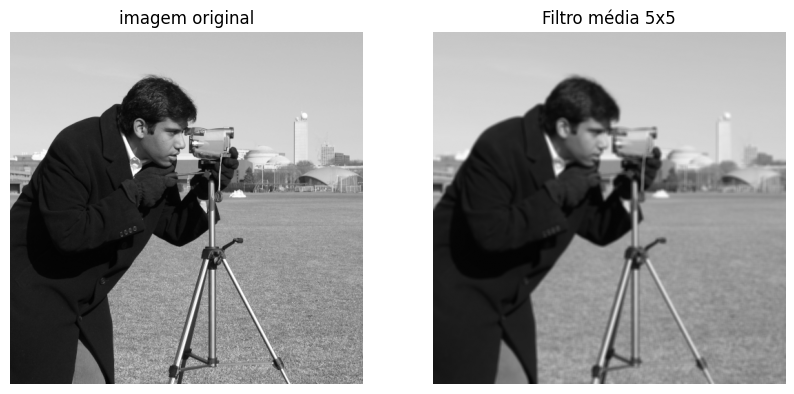

In [5]:
def filtro_media(img, tamanho=5):
  kernel = np.ones((tamanho, tamanho)) / (tamanho * tamanho)
  return convolucao(img, kernel)


img_media = filtro_media(img, 5)
implot(img, img_media, 'média', '5x5')

### 3 - Filtro de mediana (não-linear)

Substitui cada pixel pela mediana da vizinhança (valor central após ordenar). Ótimo para remover ruído sal e pimenta preservando bordas.

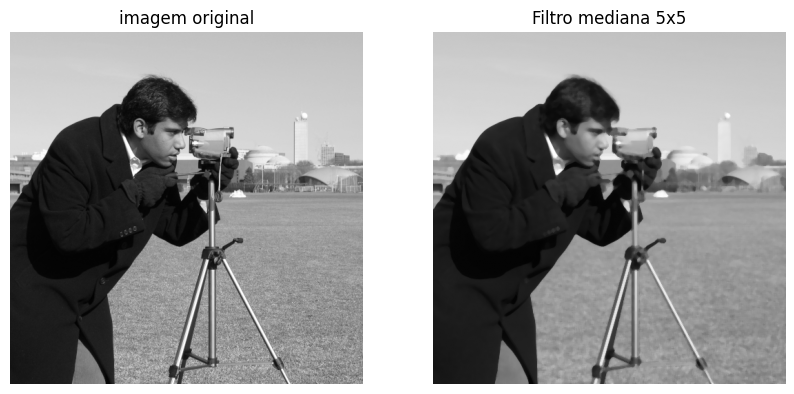

In [6]:
def calcular_mediana(janela):
  valores = np.sort(janela.ravel())
  return valores[len(valores) // 2]


def filtro_mediana(img, tamanho=5):
  return convolucao_nao_linear(img, tamanho, calcular_mediana)


img_mediana = filtro_mediana(img, 5)
implot(img, img_mediana, 'mediana', '5x5')

### 4 - Filtro de moda (não-linear)

Substitui cada pixel pelo valor que mais se repete na vizinhança. Em caso de empate, é escolhido o menor valor de intensidade.

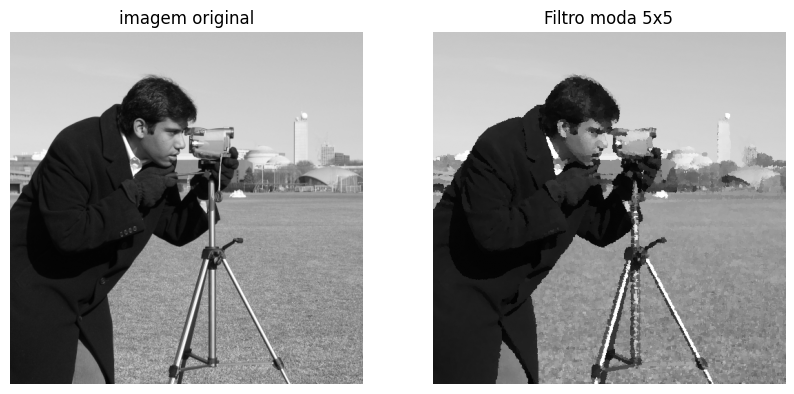

In [7]:
def calcular_moda(janela):
  contagem = np.bincount(janela.ravel(), minlength=256)  # histograma da janela
  return np.argmax(contagem)  # em empate, retorna o menor valor


def filtro_moda(img, tamanho=5):
  return convolucao_nao_linear(img, tamanho, calcular_moda)


img_moda = filtro_moda(img, 5)
implot(img, img_moda, 'moda', '5x5')

### 5 - Filtro de máxima (não-linear)

Substitui cada pixel pelo maior valor da vizinhança. Tem efeito de dilatação: regiões claras crescem e regiões escuras encolhem.

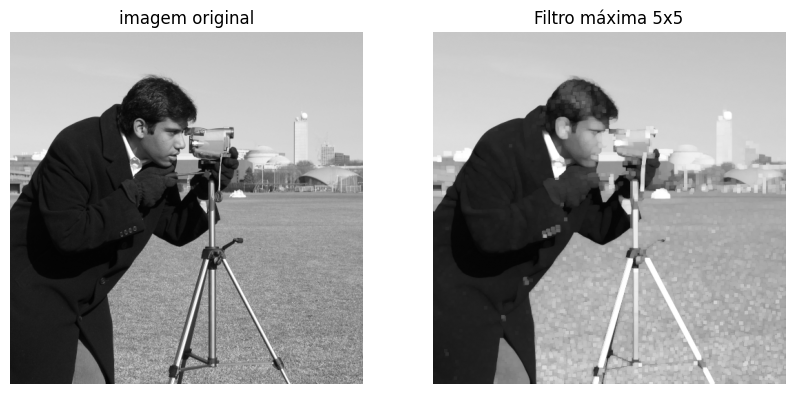

In [8]:
def calcular_maximo(janela):
  maximo = janela[0, 0]
  for valor in janela.ravel():
    if valor > maximo:
      maximo = valor
  return maximo


def filtro_maxima(img, tamanho=5):
  return convolucao_nao_linear(img, tamanho, calcular_maximo)


img_maxima = filtro_maxima(img, 5)
implot(img, img_maxima, 'máxima', '5x5')

### 6 - Comparação geral

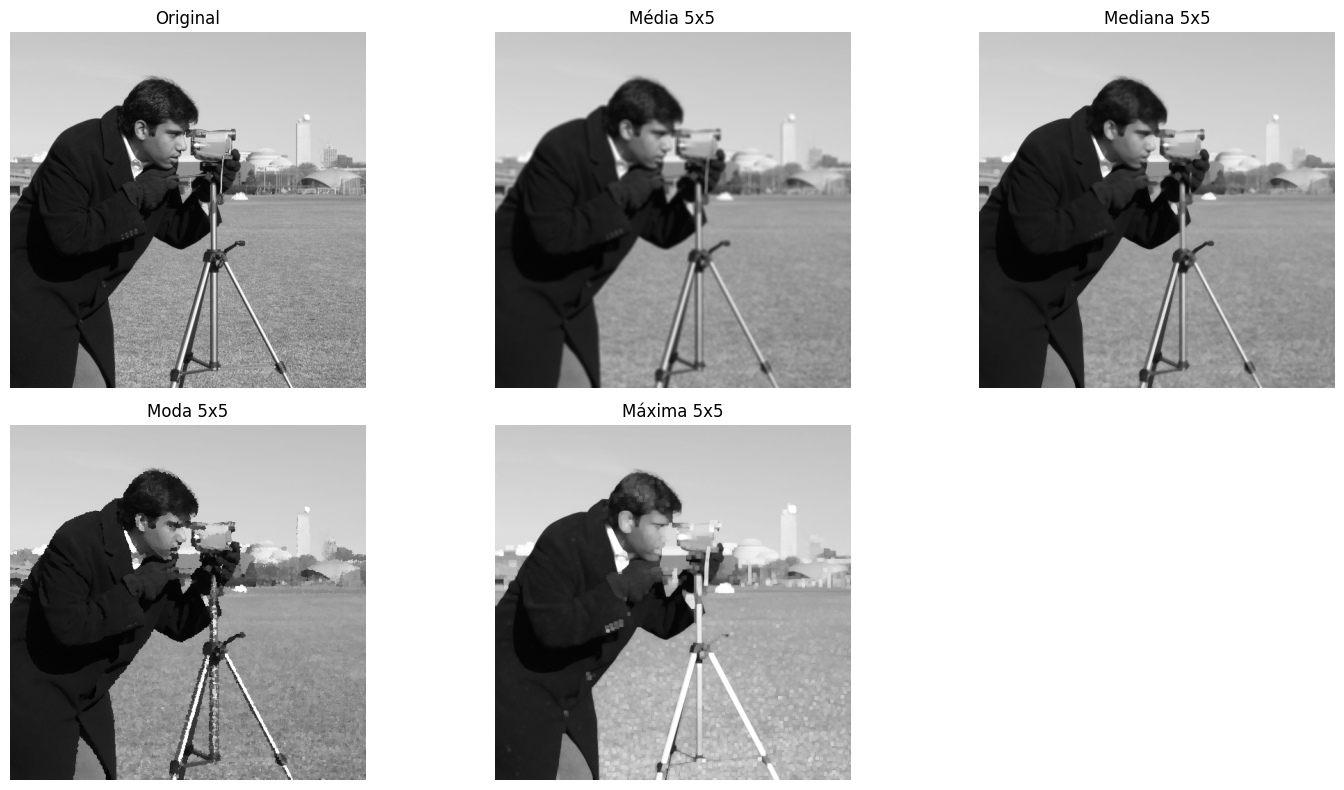

In [9]:
resultados = [
  ('Original', img),
  ('Média 5x5', img_media),
  ('Mediana 5x5', img_mediana),
  ('Moda 5x5', img_moda),
  ('Máxima 5x5', img_maxima),
]

plt.figure(figsize=(15, 8))
for idx, (titulo, imagem) in enumerate(resultados, start=1):
  plt.subplot(2, 3, idx)
  plt.imshow(imagem, cmap='gray', vmin=0, vmax=255)
  plt.title(titulo)
  plt.axis('off')
plt.tight_layout()
plt.show()